# 3. Estimate the XYZ spectral matrix

## Goal
Fit the **stationary XYZ time series** from notebook 1 with the vanilla
multivariate model in LogPSplinePSD. No parametric noise levels or reference
correction are fitted in this lesson.

The method follows the inverse-Cholesky spline construction in
[Vajpeyi et al., arXiv:2607.04833](https://arxiv.org/abs/2607.04833).
The pinned library marginalises Gaussian cross-channel coefficients. This
walkthrough uses VI for a quick point reconstruction, rather than reproducing
the paper's NUTS uncertainty study.

## Setup
The input is the saved real time series, not simulated independent powers.
We start below 25 mHz; the next lesson addresses moving response nulls across
the full analysis band.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from log_psplines import SpectralMatrix, StationaryConfig, TimeSeries, fit
from log_psplines.preprocessing.coarse_grain import CoarseGrainConfig

from lisa_case_studies.notebook_tools import COLORS, matrix_errors, style
from lisa_case_studies.tutorial_data import MatrixSimulation, load_data, workspace

style()
data = load_data("stationary_xyz")
series = TimeSeries(data["xyz"], data["time"])

## Step 1 — Specify the multivariate spline
The library writes $S^{-1}=T^\dagger D^{-1}T$, with positive diagonal $D$
and complex lower-triangular regression coefficients in $T$. Splines model
all nine real fields for three channels. Positive definiteness is built into
the model; XYZ are not treated as independent.

Use eight non-overlapping Hann-tapered blocks, an adaptive frequency
partition, and the same library prior used by its standard multivariate fit.

In [2]:
config = StationaryConfig(
    method="vi",
    Nb=8,
    wishart_window="hann",
    fmin=0.4e-3,
    fmax=25e-3,
    n_knots=18,
    knot_kwargs={"method": "log"},
    coarse_grain_config=CoarseGrainConfig(
        enabled=True,
        method="adaptive",
        Nc=None,
        tolerance=0.25,
        max_bin_width=8,
        pilot_window=31,
    ),
    vi_steps=6000,
    vi_lr=0.01,
    vi_guide="mvn",
    vi_posterior_draws=96,
    vi_early_stopping=False,
    vi_progress_bar=False,
    verbose=False,
    rng_key=17,
)
result = fit(series, config)

|00:00| LogPSpline | INFO | Coarse-grained multivariate FFT (adaptive): CoarseGrainSpec(Nc=138, Nl=1008, widths=1..8) (kept 13.7%, decimated 86.3%).


W1106 12:12:44.415788 2372837 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.


## Step 2 — Reconstruct the channel PSDs
Take the mean of reconstructed spectral matrices. Averaging positive-definite
matrices preserves positive definiteness; elementwise medians need not.
The library has already restored physical channel units.

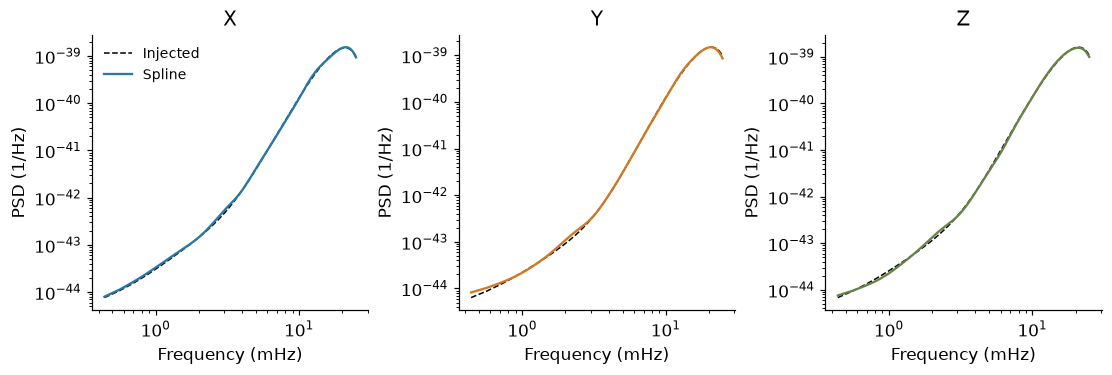

In [3]:
frequency = np.asarray(result.frequency)
estimate = np.asarray(result.spectral_density).mean(axis=(0, 1))
frozen = MatrixSimulation(
    len(data["time"]), float(data["dt"]), np.array([0.0]), data["light_times"][None]
)
truth = frozen.spectrum(np.array([0.0]), frequency)[0]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), layout="constrained")
for j, (ax, channel) in enumerate(zip(axes, "XYZ", strict=True)):
    ax.loglog(frequency * 1000, truth[:, j, j].real, "k--", lw=1, label="Injected")
    ax.loglog(
        frequency * 1000, estimate[:, j, j].real, color=COLORS[channel], label="Spline"
    )
    ax.set(xlabel="Frequency (mHz)", ylabel="PSD (1/Hz)", title=channel)
axes[0].legend(fontsize=9, frameon=False)
plt.show()

## Step 3 — Inspect the complex cross spectrum
$S_{XY}=E[\widetilde X\widetilde Y^*]$ includes both magnitude and phase.
Its real and imaginary parts can have either sign. Diagonal-only estimation
cannot recover this information.

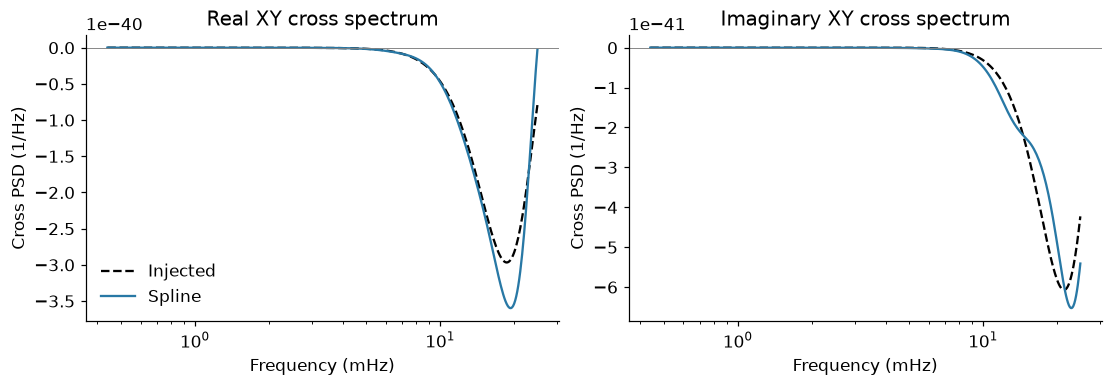

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
for ax, part, title in zip(
    axes,
    (np.real, np.imag),
    ("Real XY cross spectrum", "Imaginary XY cross spectrum"),
    strict=True,
):
    ax.semilogx(frequency * 1000, part(truth[:, 0, 1]), "k--", label="Injected")
    ax.semilogx(
        frequency * 1000, part(estimate[:, 0, 1]), color=COLORS["X"], label="Spline"
    )
    ax.axhline(0, color="0.5", lw=0.6)
    ax.set(xlabel="Frequency (mHz)", ylabel="Cross PSD (1/Hz)", title=title)
axes[0].legend(frameon=False)
plt.show()

## Step 4 — Inspect coherence
Magnitude-squared coherence is $|S_{ij}|^2/(S_{ii}S_{jj})$. Here it is
computed from the same point spectral matrix used above.

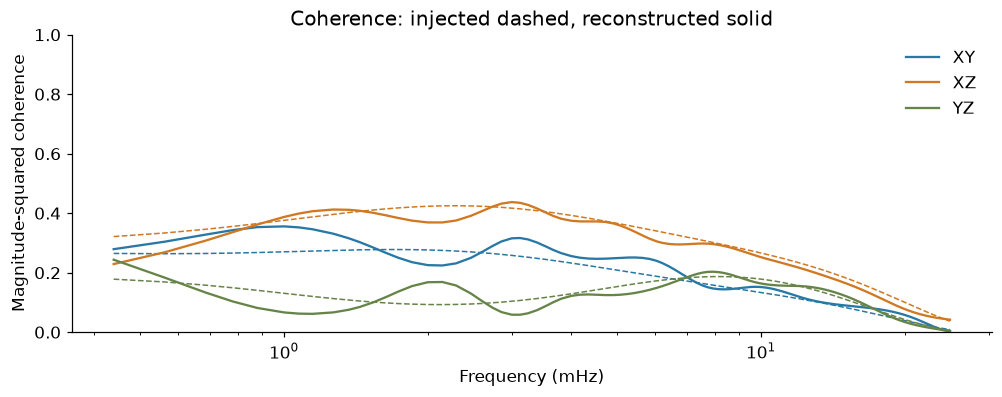

In [5]:
coherence_fit = np.asarray(SpectralMatrix.coherence(estimate))
coherence_truth = np.asarray(SpectralMatrix.coherence(truth))
fig, ax = plt.subplots(layout="constrained")
for (j, k), label, color in zip(
    ((0, 1), (0, 2), (1, 2)),
    ("XY", "XZ", "YZ"),
    (COLORS["X"], COLORS["Y"], COLORS["Z"]),
    strict=True,
):
    ax.semilogx(frequency * 1000, coherence_truth[:, j, k], color=color, ls="--", lw=1)
    ax.semilogx(frequency * 1000, coherence_fit[:, j, k], color=color, label=label)
ax.set(
    xlabel="Frequency (mHz)",
    ylabel="Magnitude-squared coherence",
    ylim=(0, 1),
    title="Coherence: injected dashed, reconstructed solid",
)
ax.legend(frameon=False)
plt.show()

## Checks
Verify Hermitian symmetry, positive definiteness, and that theta was actually
marginalised and restored. These checks do not establish calibrated VI
uncertainty or eliminate finite-window bias.

In [6]:
np.testing.assert_allclose(
    estimate, estimate.conj().swapaxes(-1, -2), rtol=1e-10, atol=1e-55
)
assert np.linalg.eigvalsh(estimate).min() > 0
assert result.metadata["theta_parameterization"] == "marginalized"
restored = [name for name in result.posterior if name.startswith("weights_theta_")]
assert len(restored) == 6
assert np.isfinite(result.vi.losses).all()
metrics = matrix_errors(estimate, truth)
pd.DataFrame([metrics]).round(4)

,Auto log10 RMSE,Complex cross RMSE
0,0.0231,0.0454


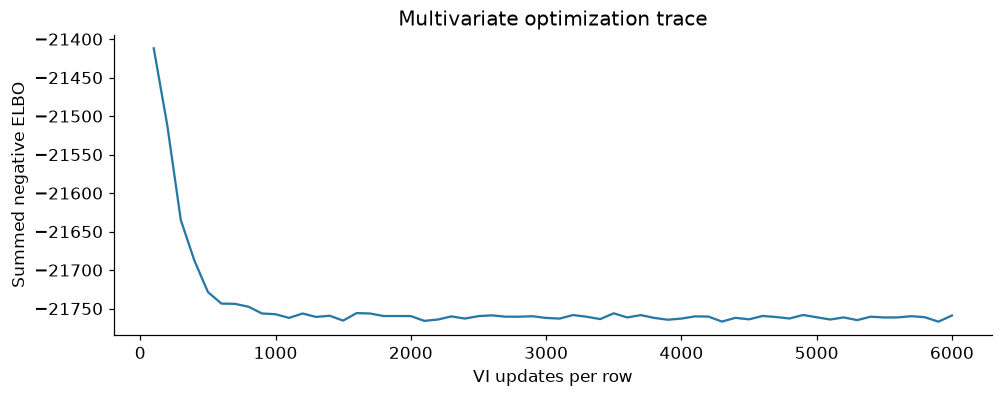

In [7]:
fig, ax = plt.subplots(layout="constrained")
loss = np.asarray(result.vi.losses)
ax.plot(np.linspace(100, config.vi_steps, len(loss)), loss, color=COLORS["X"])
ax.set(
    xlabel="VI updates per row",
    ylabel="Summed negative ELBO",
    title="Multivariate optimization trace",
)
plt.show()
np.savez_compressed(
    workspace() / "stationary_xyz_recovery.npz",
    frequency=frequency,
    estimate=estimate,
    truth=truth,
    losses=loss,
)

## Next steps
[Short-duration XYZ with gaps](04_short_xyz_gaps.ipynb) adds an evolving
reference and explicit observation windows. A gap-aware reference alone does
not make an independent-frequency likelihood exact.